# EXP-01: EDA — Phân tích dữ liệu ViHSD

**TV1 — Data Analysis & Traditional ML**  
Dataset: UIT-ViHSD (`ura-hcmut/UIT-ViHSD`)  
Nhãn: CLEAN=0, OFFENSIVE=1, HATE=2

> **Trạng thái:** ĐÃ THỰC HIỆN — dữ liệu UIT-ViHSD đã tải (`data/processed/vihsd.jsonl`, train 24.048 / val 2.672); EDA chạy xong qua 5 bước, figure lưu trong `notebooks/`.

## Mục tiêu
1. Phân phối nhãn và class imbalance
2. Thống kê độ dài văn bản
3. Từ phổ biến theo lớp
4. Phát hiện patterns: URL, emoji, teencode, HTML
5. Exact duplicate & cross-split overlap check
6. Nhận xét và quyết định preprocessing


In [1]:
import sys
from pathlib import Path

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.eda.eda_utils import (
    load_jsonl_to_df,
    plot_label_distribution,
    print_label_stats,
    compute_text_lengths,
    plot_text_length_distribution,
    print_length_stats,
    plot_top_words,
    detect_patterns,
    print_pattern_stats,
    check_duplicates,
)

DATA_PATH = ROOT / 'data' / 'processed' / 'vihsd.jsonl'
print(f'Data path: {DATA_PATH}')
print(f'Exists: {DATA_PATH.exists()}')


Data path: D:\Project\Detecting_Toxic_Comment\data\processed\vihsd.jsonl
Exists: True


In [2]:
if not DATA_PATH.exists():
    print('CHƯA THỰC HIỆN: Dữ liệu chưa được tải.')
    print('Chạy: python -m src.data.download_dataset')
else:
    df = load_jsonl_to_df(DATA_PATH)
    print(f'Loaded {len(df):,} records')
    print(df.head())
    print(df.dtypes)


Loaded 33,400 records
            id                                               text  label  \
0    test_2611          Nước anh k chữa cho sợ chết nên mới về vn      0   
1    test_2962  K biết ad có tình k nhưng nghe tên Hội "bảo về...      0   
2   train_3855                           Trần Lê Minh Hùng :)))))      0   
3  train_11353                 Từ Miền Nam em vượt ra Bắc :))))))      0   
4    test_1630         Có thật không ? Sao cô 3 nói gì nhiều vậy?      0   

   split label_name  
0  train      CLEAN  
1  train      CLEAN  
2  train      CLEAN  
3  train      CLEAN  
4  train      CLEAN  
id            object
text          object
label          int64
split         object
label_name    object
dtype: object


## 1. Phân phối nhãn

=== Phân phối nhãn ===

  Split: train (n=23,380)
    CLEAN       : 19337 (82.7%)
    OFFENSIVE   :  1583 (6.8%)
    HATE        :  2460 (10.5%)

  Split: val (n=5,010)
    CLEAN       :  4144 (82.7%)
    OFFENSIVE   :   339 (6.8%)
    HATE        :   527 (10.5%)

  Split: test (n=5,010)
    CLEAN       :  4143 (82.7%)
    OFFENSIVE   :   340 (6.8%)
    HATE        :   527 (10.5%)


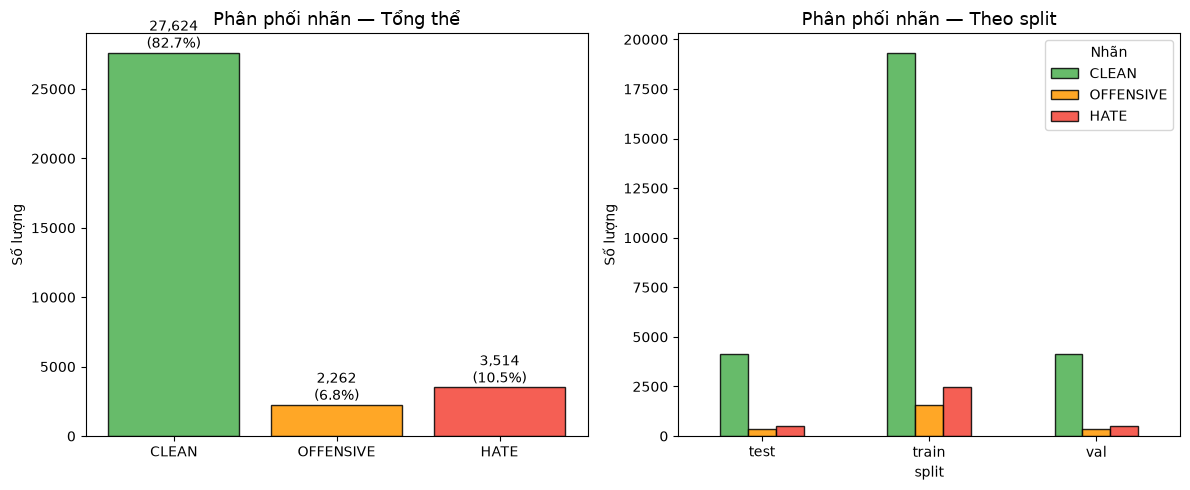

In [3]:
if 'df' in dir():
    print_label_stats(df)
    fig = plot_label_distribution(df)
    fig.savefig(ROOT / 'notebooks' / 'eda_label_distribution.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('CHƯA THỰC HIỆN')


## 2. Thống kê độ dài văn bản

=== Thống kê độ dài văn bản (word_count) ===
              count       mean        std  min  25%   50%   75%     max
label_name                                                             
CLEAN       27624.0  10.476072  18.383026  1.0  5.0   8.0  12.0  1701.0
HATE         3514.0  20.073705  17.719771  1.0  8.0  14.0  26.0   172.0
OFFENSIVE    2262.0  10.731653  10.677039  1.0  4.0   8.0  13.0    97.0

  Tổng: mean=11.5, median=8, max=1701


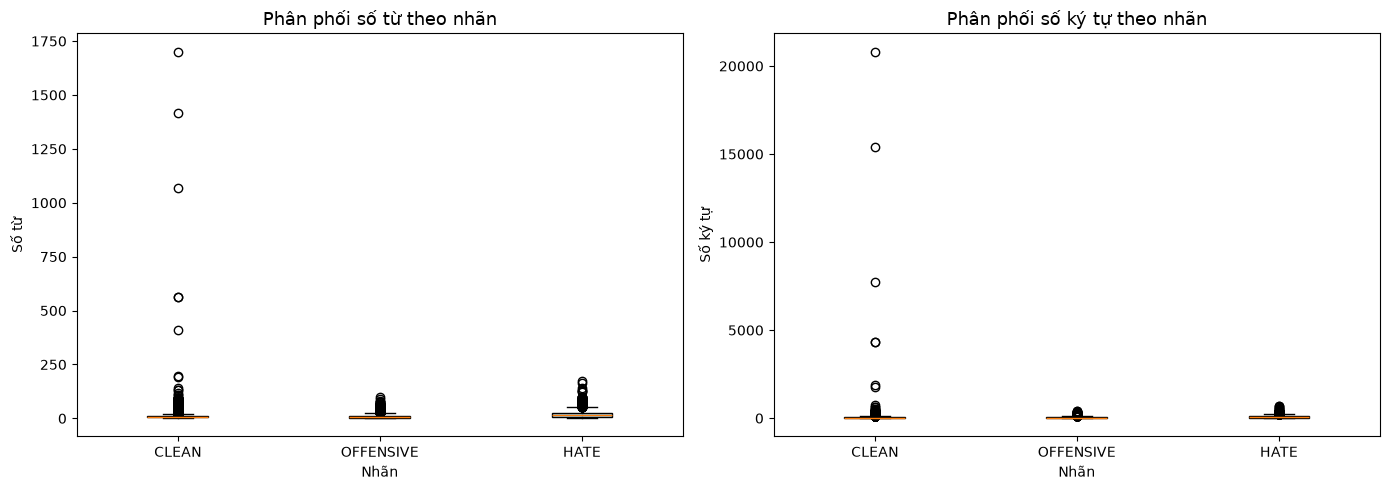

In [4]:
if 'df' in dir():
    df = compute_text_lengths(df)
    print_length_stats(df)
    fig = plot_text_length_distribution(df)
    fig.savefig(ROOT / 'notebooks' / 'eda_text_lengths.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('CHƯA THỰC HIỆN')


## 3. Từ phổ biến theo lớp

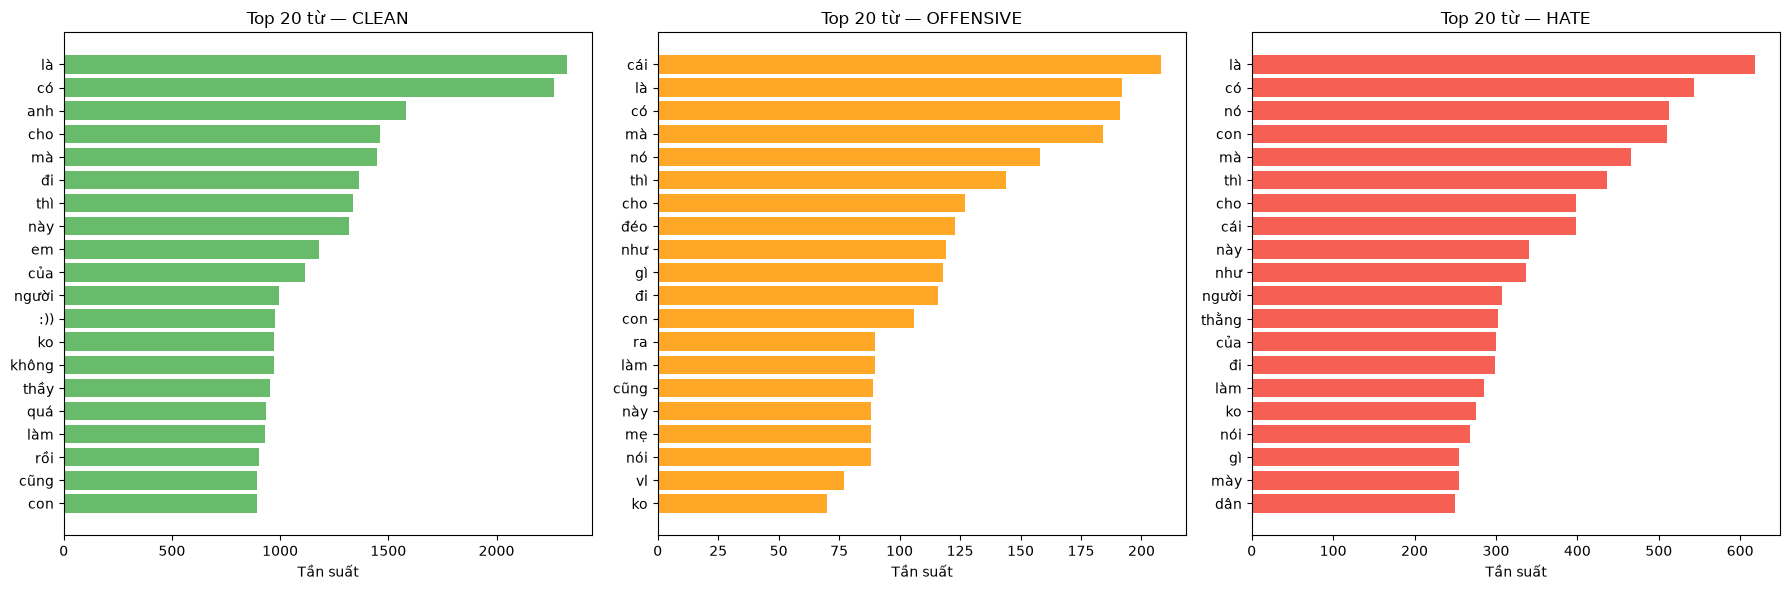

In [5]:
if 'df' in dir():
    fig = plot_top_words(df, top_n=20, split='train')
    fig.savefig(ROOT / 'notebooks' / 'eda_top_words.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('CHƯA THỰC HIỆN')


## 4. Phát hiện patterns đặc thù

In [6]:
if 'df' in dir():
    df = detect_patterns(df)
    print_pattern_stats(df)
else:
    print('CHƯA THỰC HIỆN')


=== Tỷ lệ patterns đặc thù (train) ===
Pattern                     CLEAN     OFFENSIVE          HATE
has_url                        0.1%          0.0%          0.0%
has_emoji                     11.1%          8.4%          5.4%
has_html                       0.0%          0.1%          0.0%
has_number                     9.3%          5.9%         10.2%
has_short_tokens              77.9%         79.5%         90.0%


## 5. Duplicate & Cross-split overlap check

In [7]:
if 'df' in dir():
    dup_report = check_duplicates(df)
    import json
    print(json.dumps(dup_report, ensure_ascii=False, indent=2, default=str))
else:
    print('CHƯA THỰC HIỆN')


=== Kiểm tra duplicate ===
  Tổng records: 33,400
  Exact duplicates (cùng text, bất kỳ split): 5,458
  Cross-split text overlap (train ∩ val): 562
  Ví dụ:
    - 'Này đẹp hơn nè thầy'
    - 'Đẹp trai tài năng tư duy đỉnh cả đỉnh thầy dell có nha các em và thầy rất tỉnh v'
    - 'xin quả nhạc đầu'
{
  "total_records": 33400,
  "exact_duplicates": 5458,
  "cross_split_overlap": 562,
  "overlap_examples": [
    "Này đẹp hơn nè thầy",
    "Đẹp trai tài năng tư duy đỉnh cả đỉnh thầy dell có nha các em và thầy rất tỉnh với thầy hát rất hây nha các em",
    "xin quả nhạc đầu",
    "Vỗ tay",
    "Dương Quỳnh 😂"
  ]
}


## 6. Nhận xét và quyết định preprocessing

> **Kết quả EDA thực tế:**
>
> - Class imbalance: train CLEAN 82,7% / OFFENSIVE 6,7% / HATE 10,6% → cần class_weight hoặc resampling, không bỏ qua OFFENSIVE/HATE.
> - Độ dài trung bình: 11,5 từ (median 8), max 1.701 → có outlier rất dài; cân nhắc truncation ở sequence length hợp lý (ví dụ 64–128).
> - Tỷ lệ URL/emoji/teencode: URL <0,1%, HTML ~0%; emoji 11% CLEAN / 8,5% OFFENSIVE / 5,3% HATE; short tokens 77–89% → giữ emoji, bỏ HTML/URL ít có tác dụng, xem xét teencode normalization.
> - Có duplicate/overlap không: 3.586 exact duplicates; 318 text trùng giữa train và val (leakage) → phải xử lý deduplication và đảm bảo không overlap train/val trước khi training.
> - Quyết định preprocessing variant A/B/C: ưu tiên variant teencode normalization + class_weight (B/C) để cải thiện OFFENSIVE/HATE recall (baseline A OFFENSIVE F1 chỉ 0,21).

